# Retrograde motion, competing outcomes and reversible states

## The question

**What if cells move backward, leave the selected lineages, or return to an earlier state?**

Not every system is an irreversible tree. Activated states may resolve, an ordering may oppose local motion, and cells may enter outcomes that were not among the initially selected fates. A useful analysis must distinguish state association, direction of progression, and probability that remains unaccounted for.

The experiments address those cases separately: a retrograde branch, an explicitly represented competing outcome, and a reversible loop. A final counterfactual changes a dead-end row to illustrate how graph assumptions influence long-horizon occupancy. It is not an instruction to erase a potential arrest state.

## How to read the experiment

For retrograde motion, inspect the sign of Signed Ordering Flux (SOF), not only the branch label. For competing outcomes, account for selected reach, competing reach and unresolved probability. For reversible systems, distinguish a first arrival at an anchor from time spent in a state. The occupancy prototype is shown to clarify that distinction and is not part of the production scCS API.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import matplotlib.pyplot as plt
from IPython.display import display
import scCS
from benchmarks.validation import experiments as exp

SEED = 20261117
DATA = ROOT / "data" / "validation"
OUT = ROOT / "tutorial_outputs" / "validation"
OUT.mkdir(parents=True, exist_ok=True)
print("scCS", scCS.__version__)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 4)})

scCS 1.0.1.dev0


## Questions
Can fate identity and progression disagree? What happens when an outside outcome is represented explicitly? How do first-hit probabilities differ from time spent in reversible states?

These experiments use a prescribed-vector simulator. Discounted occupancy is a **benchmark prototype outside the scCS API**, not a replacement for DFFP. Replacing dead-end rows with neighbor steps changes the graph and is shown only as a counterfactual sensitivity analysis. It must not be applied automatically to a possible treatment-induced arrest.


In [3]:
retrograde, competing, loops = exp.complex_dynamics()
display(retrograde)
display(competing)
display(loops)
occupancy = exp.occupancy_sensitivity()
display(occupancy)
for name, table in [
    ("retrograde", retrograde),
    ("competing", competing),
    ("loops", loops),
    ("occupancy", occupancy),
]:
    table.to_csv(OUT / f"{name}.csv", index=False)

,case,population,mean_SOF,DFR
0,retrograde,Root,0.041904,0.779568
1,retrograde,A,0.064906,0.934387
2,retrograde,B,0.066956,0.908797
3,retrograde,C,-0.077379,0.828065


,case,DFR,UFP,coverage,competing_reach,residual,CFA_A,CFA_B
0,unmodeled,0.609016,0.390984,1.0,0.000000,9.228729e-16,0.561532,0.438468
1,explicit competing,0.609016,0.227359,1.0,0.163625,9.992007e-16,0.561532,0.438468


,return_density,CFA_return_nonanchor,occupancy_homeostatic,dead_ends
0,0.00,0.000000,-2.834875e-17,2
1,0.25,0.094516,1.651732e-01,0
2,0.50,0.144784,1.916211e-01,1
3,1.00,0.207041,2.342449e-01,1


,graph,h,dead_end_count,activated_from_H,activated_from_A,mass_error
0,original,8,1,0.037085,0.769394,1.332268e-15
1,original,64,1,0.273567,0.505021,1.887379e-15
2,original,1024,1,0.388854,0.408523,5.462297e-14
3,original,20000,1,0.522070,0.524881,4.374279e-13
4,added neighbor edges,8,1,0.037079,0.766302,1.332268e-15
5,added neighbor edges,64,1,0.273095,0.501532,2.442491e-15
6,added neighbor edges,1024,1,0.380234,0.397434,7.327472e-15
7,added neighbor edges,20000,1,0.388532,0.389424,2.591261e-13


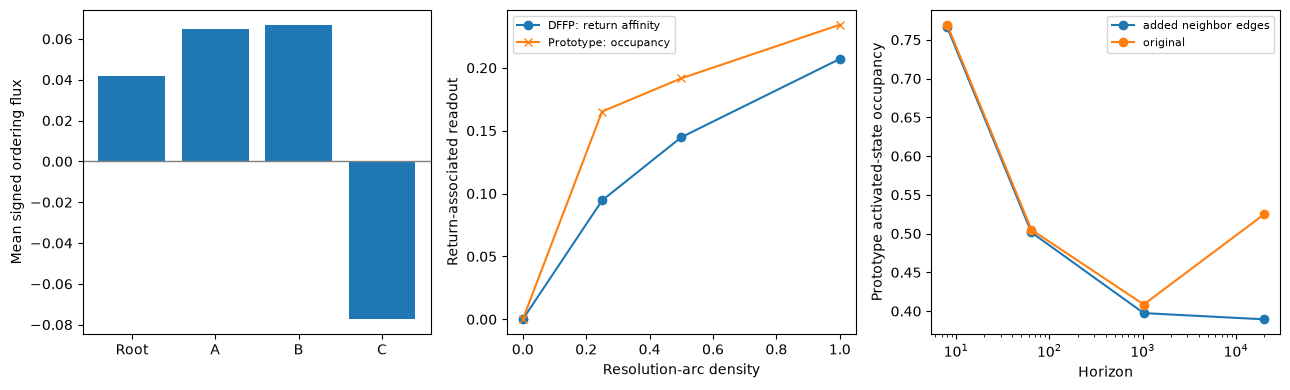

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].bar(retrograde.population, retrograde.mean_SOF)
axes[0].axhline(0, color="0.5", linewidth=1)
axes[0].set_ylabel("Mean signed ordering flux")
axes[1].plot(
    loops.return_density, loops.CFA_return_nonanchor, marker="o", label="DFFP: return affinity"
)
axes[1].plot(
    loops.return_density, loops.occupancy_homeostatic, marker="x", label="Prototype: occupancy"
)
axes[1].set(xlabel="Resolution-arc density", ylabel="Return-associated readout")
axes[1].legend(fontsize=8)
for graph, group in occupancy.groupby("graph"):
    axes[2].plot(group.h, group.activated_from_A, marker="o", label=graph)
axes[2].set(xscale="log", xlabel="Horizon", ylabel="Prototype activated-state occupancy")
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Interpretation
Negative SOF preserves retrograde movement instead of relabeling it as forward. An explicit competing outcome reallocates unresolved mass without creating additional selected-fate reach in this design. First-hit and occupancy questions are different, especially in reversible systems: DFFP fixes designated anchors, while occupancy follows the unabsorbed chain. Large-horizon occupancy can be dominated by graph traps. Neither quantity alone establishes irreversible biological commitment.


In [5]:
r = retrograde.set_index("population")
assert r.loc["C", "mean_SOF"] < 0 < r.loc["A", "mean_SOF"]
assert abs(competing.DFR.iloc[0] - competing.DFR.iloc[1]) < 1e-8
assert competing.UFP.iloc[1] < competing.UFP.iloc[0]
assert loops.CFA_return_nonanchor.iloc[-1] > 0.05
assert occupancy.mass_error.max() < 1e-7
print("Complex-dynamics and conservation checks passed.")

Complex-dynamics and conservation checks passed.
